# Where Does the NBA Split? Visualizing the East–West Conference Divide with an SVM

The NBA assigns its 30 teams to an Eastern and a Western conference, ostensibly by geography.
But geography is messy: Memphis sits on the east bank of the Mississippi yet plays in the West,
and the league has redrawn the line after every relocation and expansion.

This notebook treats the conference split as a binary classification problem:

- **Features:** each team's arena location (longitude, latitude)
- **Label:** conference (East / West)
- **Model:** a linear support vector machine — the maximum-margin separator is exactly the
  "fairest" straight line you could draw between the two conferences
- **Output:** the SVM's decision boundary projected onto a map of North America


In [1]:
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## The data

`data/arenas.csv` is a hand-curated table of all 30 NBA arenas (2025–26 season) with
their coordinates. Longitude is negative because all of these are west of Greenwich.

In [2]:
arenas = pd.read_csv("../data/arenas.csv")
assert len(arenas) == 30 and arenas["conference"].value_counts().eq(15).all()
arenas.sort_values("lon").head(8)

,team,conference,arena,city,lat,lon
26,Portland Trail Blazers,West,Moda Center,Portland,45.5316,-122.6668
17,Golden State Warriors,West,Chase Center,San Francisco,37.7680,-122.3877
27,Sacramento Kings,West,Golden 1 Center,Sacramento,38.5802,-121.4997
19,LA Clippers,West,Intuit Dome,Los Angeles,33.9450,-118.3417
20,Los Angeles Lakers,West,Crypto.com Arena,Los Angeles,34.0430,-118.2673
25,Phoenix Suns,West,Mortgage Matchup Center,Phoenix,33.4457,-112.0712
29,Utah Jazz,West,Delta Center,Salt Lake City,40.7683,-111.9011
16,Denver Nuggets,West,Ball Arena,Denver,39.7487,-105.0077


## A basemap of North America

We pull country and state/province boundaries from [Natural Earth](https://www.naturalearthdata.com/)
(public domain, 1:110m scale) and cache them in `data/naturalearth/` so the download only happens once.

In [3]:
NE_BASE = "https://naciscdn.org/naturalearth/110m/cultural"
NE_CACHE = Path("../data/naturalearth")


def fetch_naturalearth(layer: str) -> gpd.GeoDataFrame:
    NE_CACHE.mkdir(parents=True, exist_ok=True)
    path = NE_CACHE / f"{layer}.zip"
    if not path.exists():
        urllib.request.urlretrieve(f"{NE_BASE}/{layer}.zip", path)
    return gpd.read_file(path)


countries = fetch_naturalearth("ne_110m_admin_0_countries")
states = fetch_naturalearth("ne_110m_admin_1_states_provinces")

# Map window: covers every arena from Miami (25.8°N) to Portland/Toronto, with breathing room.
XLIM, YLIM = (-128, -64), (22, 53)


def plot_basemap(ax, land=True):
    if land:
        countries.plot(ax=ax, facecolor="0.95", edgecolor="none", zorder=0)
    countries.boundary.plot(ax=ax, color="0.4", linewidth=0.8, zorder=2)
    states.boundary.plot(ax=ax, color="0.6", linewidth=0.3, zorder=2)
    ax.set_xlim(XLIM)
    ax.set_ylim(YLIM)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

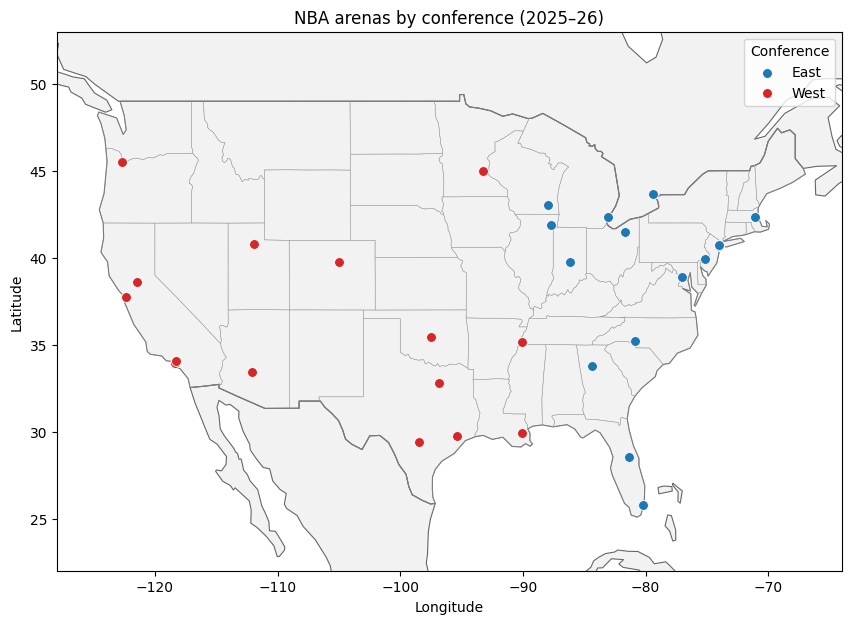

In [4]:
COLORS = {"East": "#1f77b4", "West": "#d62728"}

fig, ax = plt.subplots(figsize=(12, 7))
plot_basemap(ax)
for conf, group in arenas.groupby("conference"):
    ax.scatter(group["lon"], group["lat"], color=COLORS[conf], label=conf,
               s=50, zorder=3, edgecolor="white", linewidth=0.6)
ax.legend(title="Conference")
ax.set_title("NBA arenas by conference (2025–26)")
plt.show()

## Fitting the SVM

A linear SVM finds the separating line that maximizes the margin — the distance to the
closest points on either side. Those closest points are the *support vectors*: they alone
determine where the boundary sits, so for us they are literally the border teams of each conference.

We standardize the features inside a pipeline (longitude spans ~50°, latitude ~20°, and SVMs
are scale-sensitive) and use a large `C` since we expect the conferences to be cleanly separable.

In [5]:
X = arenas[["lon", "lat"]]
y = arenas["conference"]

model = make_pipeline(StandardScaler(), SVC(kernel="linear", C=10))
model.fit(X, y)
svc = model.named_steps["svc"]

print(f"Training accuracy: {model.score(X, y):.0%}")
print(f"Support vectors: {len(svc.support_)} of {len(arenas)} teams")
arenas.iloc[svc.support_][["team", "conference", "city", "lon"]]

Training accuracy: 100%
Support vectors: 5 of 30 teams


,team,conference,city,lon
0,Atlanta Hawks,East,Atlanta,-84.3963
4,Chicago Bulls,East,Chicago,-87.6742
9,Milwaukee Bucks,East,Milwaukee,-87.9172
21,Memphis Grizzlies,West,Memphis,-90.0506
22,Minnesota Timberwolves,West,Minneapolis,-93.2761


## The decision boundary, on the map

`DecisionBoundaryDisplay` evaluates the fitted pipeline on a grid; we lay its shaded regions
under the basemap, draw the boundary (solid) and the margins (dashed), and circle the support vectors.

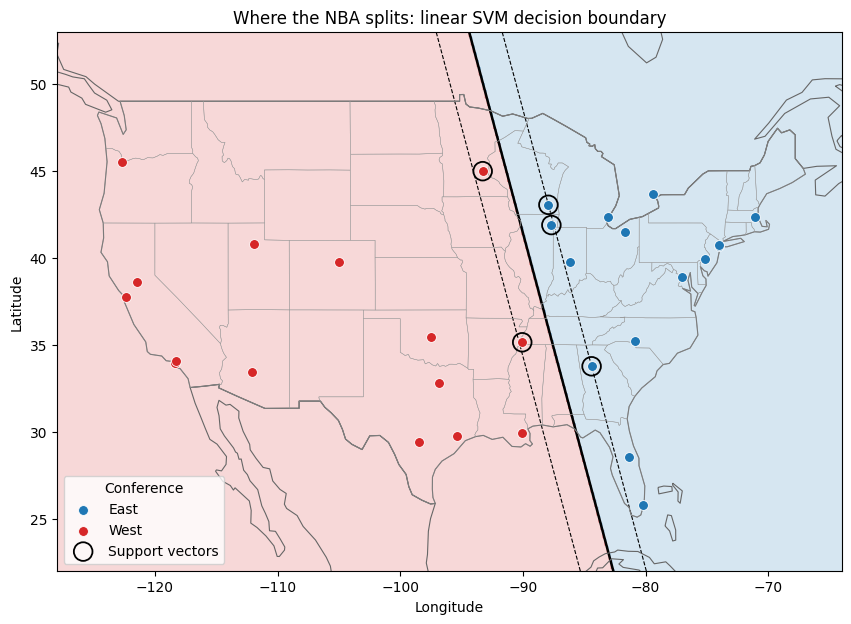

In [6]:
fig, ax = plt.subplots(figsize=(12, 7))

# Two corner points spanning the map window, so the display's grid covers the whole map
# (it derives its range from X) while keeping the column names the pipeline was fit with.
X_extent = pd.DataFrame({"lon": XLIM, "lat": YLIM})

DecisionBoundaryDisplay.from_estimator(
    model, X_extent, response_method="predict", plot_method="contourf",
    cmap=ListedColormap([COLORS[c] for c in svc.classes_]), alpha=0.18,
    grid_resolution=400, ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    model, X_extent, response_method="decision_function", plot_method="contour",
    levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"],
    linewidths=[0.8, 1.8, 0.8], grid_resolution=400, ax=ax,
)

plot_basemap(ax, land=False)
for conf, group in arenas.groupby("conference"):
    ax.scatter(group["lon"], group["lat"], color=COLORS[conf], label=conf,
               s=50, zorder=3, edgecolor="white", linewidth=0.6)
ax.scatter(X.iloc[svc.support_]["lon"], X.iloc[svc.support_]["lat"],
           facecolor="none", edgecolor="black", s=180, linewidth=1.3,
           zorder=4, label="Support vectors")
ax.legend(title="Conference", loc="lower left")
ax.set_title("Where the NBA splits: linear SVM decision boundary")
plt.show()

## Takeaways

- The conferences are **linearly separable**: a single straight line classifies all 30 teams
  correctly, running near 89°W — roughly down the Mississippi.
- Five teams are support vectors, the literal border of each conference: Memphis and
  Minnesota pressing from the West; Milwaukee, Chicago, and Atlanta from the East.
- The boundary is *not* perfectly vertical: it leans westward as you go north, pinched
  between Atlanta and Memphis (~35°N) at the bottom and between Milwaukee and Minneapolis
  (~44°N) at the top. The margin is only a couple of degrees of longitude wide.

### Ideas to extend

- Swap in an RBF kernel and watch it carve the same (boring, because the data is separable) split —
  a nice demonstration that kernel complexity buys nothing here.
- Re-run on historical league maps (e.g. 2000–01, when Memphis was still Vancouver and the
  Hornets were in Charlotte) to see how the margin has shifted.
- Use great-circle distances and a precomputed kernel instead of treating lon/lat as Euclidean.